*Realizado por: EDIXON HARBEY RUBIANO ROBAYO*



El objetivo de este análisis será calcular el total recaudado y el número de pasajeros por cada Estación.

# **1: Carga y exploración del dataset**

In [3]:
import pandas as pd

# Cargar el dataset
df = pd.read_csv('transacciones_transmilenio.csv')

# Mostrar las primeras 5 filas del dataset
print("Primeras filas del dataset:")
display(df.head())
print(f"\nTotal de registros a procesar: {len(df)}")

Primeras filas del dataset:


,id_transaccion,fecha_hora,estacion,ruta,tipo_tarjeta,monto_pasaje,tiempo_val_segundos
0,TRX-000001,2026-01-03 03:00:00,San Victorino,F26,Tullave Basica,3100,8
1,TRX-000002,2026-01-04 20:00:00,Calle 100,F26,Tullave Basica,3100,14
2,TRX-000003,2026-01-01 14:00:00,Calle 100,J24,Tullave Plus,2950,3
3,TRX-000004,2026-01-03 23:00:00,Calle 100,B11,Tullave Basica,2950,10
4,TRX-000005,2026-01-03 12:00:00,Banderas,G11,Credito/Debito,2950,6



Total de registros a procesar: 50000


# **2: Definir la función MAP**

La fase Map toma cada registro (fila) y emite un par clave-valor. En nuestro caso, la clave será el nombre de la Estación y el valor será una tupla con (1 pasajero, monto del pasaje).


In [4]:
def mapper(row):
    """
    Función Map:
    Entrada: Una fila del DataFrame.
    Salida: Tupla (Clave, Valor) -> (Estacion, (1, monto))
    """
    estacion = row['estacion']
    monto = row['monto_pasaje']
    return (estacion, (1, monto))

# **3: Definir la fase de SHUFFLE & SORT (Agrupación)**


En un entorno distribuido como Hadoop, esta fase agrupa automáticamente todas las emisiones del Map que comparten la misma clave. En Python puro o en este caso Google Colab, lo simulamos recolectando los valores por clave en un diccionario.

In [10]:
from collections import defaultdict

def shuffle_and_sort(mapped_data):
    """
    Agrupa los valores emitidos por el Map de acuerdo a su clave (Estación).
    """
    grouped_data = defaultdict(list)
    for key, value in mapped_data:
        grouped_data[key].append(value)
    return grouped_data

# **4: Definir la función REDUCE**


La fase Reduce procesa la lista de valores asociados a cada clave única. Aquí sumaremos la cantidad de pasajeros y el dinero recaudado por cada estación.

In [11]:
def reducer(estacion, lista_valores):
    """
    Función Reduce:
    Entrada: Clave (Estacion) y lista de valores [(1, monto1), (1, monto2), ...]
    Salida: Resultado agregado por estación.
    """
    total_pasajeros = 0
    recaudo_total = 0

    for pasajeros, monto in lista_valores:
        total_pasajeros += pasajeros
        recaudo_total += monto

    return {
        'estacion': estacion,
        'total_pasajeros': total_pasajeros,
        'recaudo_total': recaudo_total
    }

# **5: Ejecutar el Pipeline completo de MapReduce**


Ahora, unimos las tres fases (Map -> Shuffle & Sort -> Reduce) para procesar todo el dataset de los 50,000 registros y obtener los resultados consolidados.

In [12]:
# 1. Aplicar la fase MAP a cada fila del DataFrame
mapped_results = [mapper(row) for _, row in df.iterrows()]

# 2. Aplicar la fase SHUFFLE & SORT
grouped_results = shuffle_and_sort(mapped_results)

# 3. Aplicar la fase REDUCE para cada estación
final_results = []
for estacion, valores in grouped_results.items():
    resultado_reducido = reducer(estacion, valores)
    final_results.append(resultado_reducido)

# Convertir el resultado final en un DataFrame para visualizarlo ordenadamente
df_resultado = pd.DataFrame(final_results)
df_resultado = df_resultado.sort_values(by='recaudo_total', ascending=False).reset_index(drop=True)

print("--- RESULTADOS FINALES DE MAPREDUCE ---")
display(df_resultado)

--- RESULTADOS FINALES DE MAPREDUCE ---


,estacion,total_pasajeros,recaudo_total
0,San Victorino,6339,18981750
1,Ricaurte,6303,18886950
2,Portal Norte,6297,18865200
3,Portal Sur,6267,18768900
4,Universidades,6237,18693300
5,Portal 80,6210,18600150
6,Calle 100,6190,18550900
7,Banderas,6157,18431650


# **6: Análisis MapReduce Adicional - Recaudo y Uso por Tipo de Tarjeta**


Vamos a aplicar otro proceso MapReduce para entender qué medio de pago (Tullave Plus, Básica, Crédito/Débito) genera más volumen de transacciones y recaudo.

In [13]:
# --- MAPPER PARA TIPO DE TARJETA ---
def mapper_tarjeta(row):
    """Emite (Tipo_Tarjeta, (1, monto_pasaje))"""
    return (row['tipo_tarjeta'], (1, row['monto_pasaje']))

# Ejecutar el proceso MapReduce para tarjetas
mapped_tarjetas = [mapper_tarjeta(row) for _, row in df.iterrows()]
grouped_tarjetas = shuffle_and_sort(mapped_tarjetas)

resultados_tarjetas = []
for tarjeta, valores in grouped_tarjetas.items():
    res = reducer(tarjeta, valores)  # Reutilizamos nuestro reducer genérico
    resultados_tarjetas.append(res)

df_tarjetas = pd.DataFrame(resultados_tarjetas).sort_values(by='recaudo_total', ascending=False).reset_index(drop=True)

print("--- RESULTADOS POR TIPO DE TARJETA ---")
display(df_tarjetas)

--- RESULTADOS POR TIPO DE TARJETA ---


,estacion,total_pasajeros,recaudo_total
0,Tullave Plus,25046,75019850
1,Tullave Basica,14933,44742350
2,Credito/Debito,10021,30016600


# **7: Análisis MapReduce Adicional - Demanda por Franja Horaria**


Transformaremos la fecha y hora para extraer la hora del día y evaluar en qué momentos se concentra el mayor flujo de pasajeros usando el paradigma.

In [14]:
# Convertir la columna fecha_hora a datetime para extraer la hora
df['hora'] = pd.to_datetime(df['fecha_hora']).dt.hour

# --- MAPPER POR HORA ---
def mapper_hora(row):
    """Emite (Hora_del_dia, (1, monto_pasaje))"""
    return (row['hora'], (1, row['monto_pasaje']))

mapped_horas = [mapper_hora(row) for _, row in df.iterrows()]
grouped_horas = shuffle_and_sort(mapped_horas)

resultados_horas = []
for hora, valores in grouped_horas.items():
    # Adaptamos el diccionario de salida para claridad
    total_pasajeros = sum(p for p, m in valores)
    recaudo = sum(m for p, m in valores)
    resultados_horas.append({'hora': f"{hora:02d}:00", 'total_pasajeros': total_pasajeros, 'recaudo_total': recaudo})

df_horas = pd.DataFrame(resultados_horas).sort_values(by='hora').reset_index(drop=True)

print("--- RESULTADOS POR FRANJA HORARIA ---")
display(df_horas)

--- RESULTADOS POR FRANJA HORARIA ---


,hora,total_pasajeros,recaudo_total
0,00:00,2442,7312800
1,01:00,2481,7431900
2,02:00,2495,7479650
3,03:00,2506,7502350
4,04:00,2040,6113850
5,05:00,2057,6161600
6,06:00,1945,5829550
7,07:00,1970,5900150
8,08:00,1953,5848500
9,09:00,1999,5986450


# **8: Visualización Gráfica de los Resultados**


Para respaldar el análisis con gráficos claros (vital para informes técnicos), añade esta celda para graficar el recaudo por estación y por hora:

/tmp/ipykernel_2049/502638080.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_resultado, x='recaudo_total', y='estacion', ax=axes[0], palette='Blues_r')


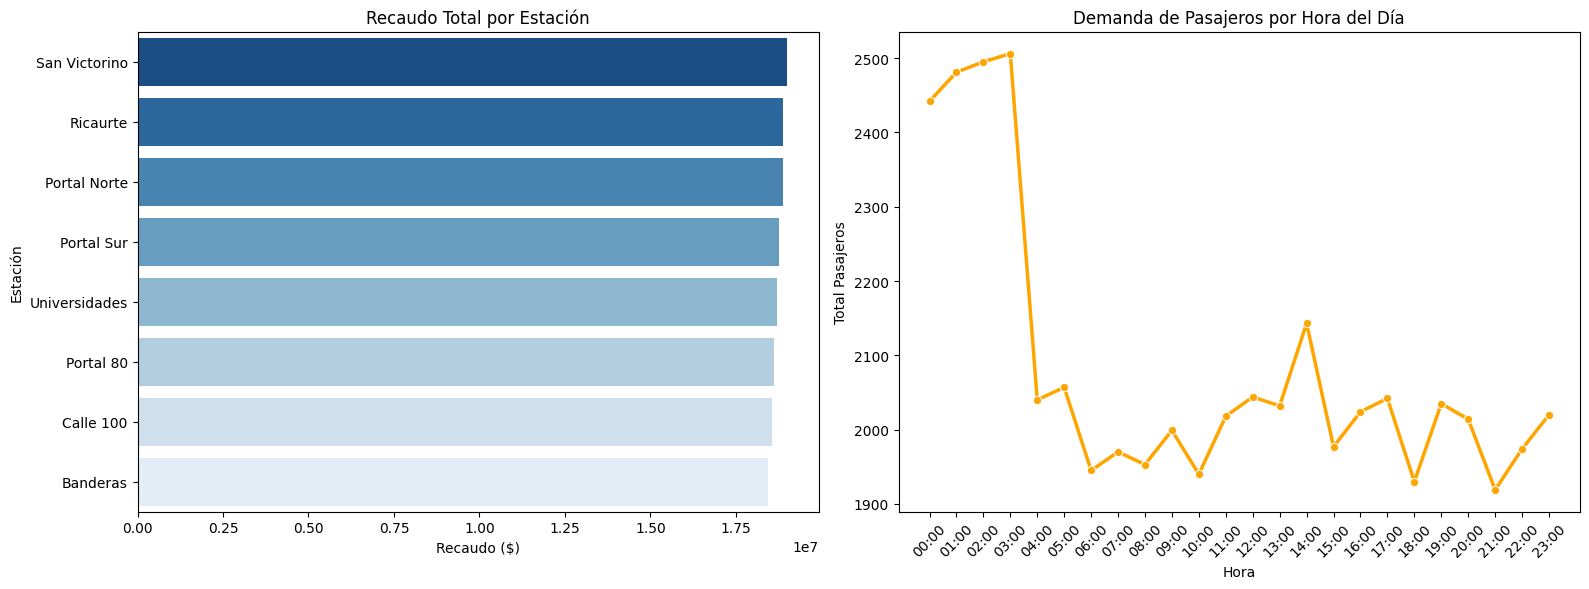

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Recaudo por Estación
sns.barplot(data=df_resultado, x='recaudo_total', y='estacion', ax=axes[0], palette='Blues_r')
axes[0].set_title('Recaudo Total por Estación')
axes[0].set_xlabel('Recaudo ($)')
axes[0].set_ylabel('Estación')

# Gráfico 2: Pasajeros por Hora
sns.lineplot(data=df_horas, x='hora', y='total_pasajeros', marker='o', ax=axes[1], color='orange', linewidth=2.5)
axes[1].set_title('Demanda de Pasajeros por Hora del Día')
axes[1].set_xlabel('Hora')
axes[1].set_ylabel('Total Pasajeros')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()